Dataset loaded/generated successfully
   Age  Study_Hours_Per_Day  Attendance_Percent  Previous_Score  \
0   17                  5.4                84.3            66.1   
1   22                  3.1                69.7            58.8   
2   21                  4.0                98.1           100.0   
3   20                  0.2                90.9            66.7   
4   20                  1.8                83.0            91.2   

   Assignment_Score  Sleep_Hours  Absences  Internet_Access  Parental_Support  \
0              76.7          6.7         3                1                 1   
1              42.6          6.7         1                1                 0   
2              61.0          8.1         4                1                 1   
3              88.9          8.3         4                1                 0   
4              73.1          6.3         8                1                 0   

   Extracurricular_Activity Performance_Level  
0                       

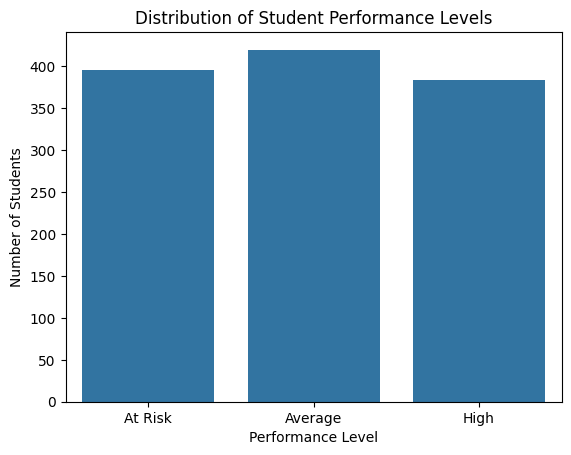

Training records: 960
Testing records: 240
\n ================== Logistic Regression ==================
              precision    recall  f1-score   support

     At Risk       0.53      0.59      0.56        79
     Average       0.39      0.29      0.33        84
        High       0.55      0.65      0.60        77

    accuracy                           0.50       240
   macro avg       0.49      0.51      0.50       240
weighted avg       0.49      0.50      0.49       240

\n ================== Decision Tree ==================
              precision    recall  f1-score   support

     At Risk       0.46      0.66      0.54        79
     Average       0.38      0.21      0.27        84
        High       0.61      0.62      0.62        77

    accuracy                           0.49       240
   macro avg       0.48      0.50      0.48       240
weighted avg       0.48      0.49      0.47       240

\n ================== Random Forest ==================
              precision 

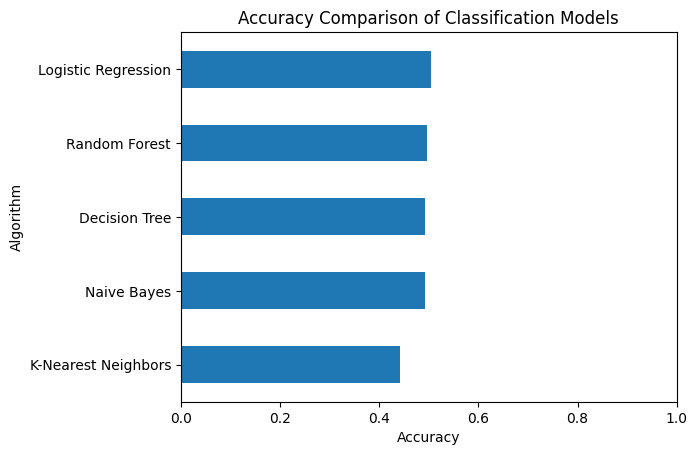

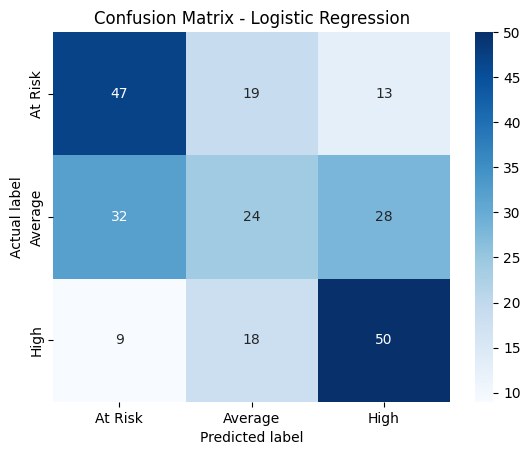

\nSAMPLE STUDENT PREDICTION
Selected model: Logistic Regression
Predicted performance level: High
\nPROJECT EXECUTION COMPLETED


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

# Create reproducible synthetic student dataset
rng = np.random.default_rng(42)
n = 1200
age = rng.integers(17, 24, n)
study_hours = np.clip(rng.normal(3.5, 1.5, n), 0.2, 9.0)
attendance = np.clip(rng.normal(82, 11, n), 40, 100)
previous_score = np.clip(rng.normal(68, 15, n), 20, 100)
assignment_score = np.clip(rng.normal(72, 14, n), 15, 100)
sleep_hours = np.clip(rng.normal(7, 1.1, n), 3.5, 10)
absences = np.clip(rng.poisson(4, n), 0, 25)
internet_access = rng.binomial(1, 0.88, n)
parental_support = rng.binomial(1, 0.68, n)
extracurricular = rng.binomial(1, 0.45, n)

latent = (0.26*study_hours + 0.025*attendance + 0.018*previous_score
          + 0.015*assignment_score + 0.10*sleep_hours - 0.075*absences
          + 1.1*internet_access + 0.8*parental_support + 0.25*extracurricular
          + rng.normal(0, 1.2, n))
q1, q2 = np.quantile(latent, [0.33, 0.68])
performance = np.where(latent < q1, "At Risk",
                       np.where(latent < q2, "Average", "High"))

df = pd.DataFrame({
    "Age": age, "Study_Hours_Per_Day": study_hours.round(1),
    "Attendance_Percent": attendance.round(1),
    "Previous_Score": previous_score.round(1),
    "Assignment_Score": assignment_score.round(1),
    "Sleep_Hours": sleep_hours.round(1), "Absences": absences,
    "Internet_Access": internet_access, "Parental_Support": parental_support,
    "Extracurricular_Activity": extracurricular,
    "Performance_Level": performance
})
print("Dataset loaded/generated successfully")
print(df.head())
print("\\nDataset shape:", df.shape)
print("\\nMissing values:\\n", df.isnull().sum())
print("\\nClass distribution:\\n", df["Performance_Level"].value_counts())

sns.countplot(data=df, x="Performance_Level",
              order=["At Risk", "Average", "High"])
plt.title("Distribution of Student Performance Levels")
plt.xlabel("Performance Level"); plt.ylabel("Number of Students"); plt.show()

X = df.drop(columns=["Performance_Level"])
y = df["Performance_Level"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))]),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=8,
                                             random_state=42),
    "K-Nearest Neighbors": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=7))]),
    "Naive Bayes": GaussianNB()
}
results, predictions = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="macro",
                                      zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="macro",
                               zero_division=0),
        "F1-score": f1_score(y_test, y_pred, average="macro",
                             zero_division=0)
    })
    print("\\n", "="*18, name, "="*18)
    print(classification_report(y_test, y_pred, zero_division=0))

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False)
print("\\nMODEL COMPARISON")
print(results_df.to_string(index=False))

results_df.sort_values("Accuracy").plot(
    x="Algorithm", y="Accuracy", kind="barh", legend=False)
plt.xlim(0, 1); plt.xlabel("Accuracy")
plt.title("Accuracy Comparison of Classification Models"); plt.show()

best_name = results_df.iloc[0]["Algorithm"]
best_model = models[best_name]
best_predictions = predictions[best_name]
cm = confusion_matrix(y_test, best_predictions,
                      labels=["At Risk", "Average", "High"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["At Risk", "Average", "High"],
            yticklabels=["At Risk", "Average", "High"])
plt.xlabel("Predicted label"); plt.ylabel("Actual label")
plt.title("Confusion Matrix - " + best_name); plt.show()

sample_student = pd.DataFrame([{
    "Age": 19, "Study_Hours_Per_Day": 4.5, "Attendance_Percent": 88.0,
    "Previous_Score": 72.0, "Assignment_Score": 78.0, "Sleep_Hours": 7.0,
    "Absences": 2, "Internet_Access": 1, "Parental_Support": 1,
    "Extracurricular_Activity": 1
}])
predicted_level = best_model.predict(sample_student)[0]
print("\\nSAMPLE STUDENT PREDICTION")
print("Selected model:", best_name)
print("Predicted performance level:", predicted_level)
print("\\nPROJECT EXECUTION COMPLETED")
